# Lab 6

You are tasked with evaluating card counting strategies for black jack. In order to do so, you will use object oriented programming to create a playable casino style black jack game where a computer dealer plays against $n$ computer players and possibly one human player. If you don't know the rules of blackjack or card counting, please google it. 

A few requirements:
* The game should utilize multiple 52-card decks. Typically the game is played with 6 decks.
* Players should have chips.
* Dealer's actions are predefined by rules of the game (typically hit on 16). 
* The players should be aware of all shown cards so that they can count cards.
* Each player could have a different strategy.
* The system should allow you to play large numbers of games, study the outcomes, and compare average winnings per hand rate for different strategies.

1. Begin by creating a classes to represent cards and decks. The deck should support more than one 52-card set. The deck should allow you to shuffle and draw cards. Include a "plastic" card, placed randomly in the deck. Later, when the plastic card is dealt, shuffle the cards before the next deal.

In [1]:

import random
class Card:
    def __init__(self, rank, suit):
        self.rank = rank
        self.suit = suit
    def __str__(self):
        return f"{self.rank} of {self.suit}"
    def __repr__(self):
        return str(self)

class Deck:
    def __init__(self, num_decks=6):
        self.num_decks = num_decks
        self.cards = []
        self.shuffle_needed = False
        self.shuffle()
        
    def shuffle(self):
        suits = ["Hearts", "Diamonds", "Clubs", "Spades"]
        ranks = ["A", "2", "3", "4", "5", "6", "7",
                 "8", "9", "10", "J", "Q", "K"]
        self.cards = []
        for i in range(self.num_decks):
            for suit in suits:
                for rank in ranks:
                    self.cards.append(Card(rank, suit))
        random.shuffle(self.cards)
        position = random.randint(1, len(self.cards) - 1)
        self.cards.insert(position, "Plastic")
        self.shuffle_needed = False

    def draw(self):
        if len(self.cards) == 0:
            raise ValueError("No cards left in the deck")
        card = self.cards.pop()
        if card == "Plastic":
            self.shuffle_needed = True
            card = self.cards.pop()
        return card

    def needs_shuffle(self):
        return self.shuffle_needed

    def remaining(self):
        return len(self.cards)


In [2]:

deck = Deck(6)
print("Cards in deck:", deck.remaining())
for i in range(5):
    card = deck.draw()
    print("Drawn:", card)
print("Remaining cards:", deck.remaining())
print("Shuffle needed:", deck.needs_shuffle())


Cards in deck: 313
Drawn: A of Clubs
Drawn: 9 of Spades
Drawn: 8 of Clubs
Drawn: K of Hearts
Drawn: 7 of Spades
Remaining cards: 308
Shuffle needed: False


2. Now design your game on a UML diagram. You may want to create classes to represent, players, a hand, and/or the game. As you work through the lab, update your UML diagram. At the end of the lab, submit your diagram (as pdf file) along with your notebook. 

3. Begin with implementing the skeleton (ie define data members and methods/functions, but do not code the logic) of the classes in your UML diagram.

In [3]:
import random
class Card:
    def __init__(self, rank, suit):
        self.rank = rank
        self.suit = suit

    def __str__(self):
        return f"{self.rank} of {self.suit}"

    def __repr__(self):
        return str(self)

class Deck:
    def __init__(self, num_decks=6):
        self.num_decks = num_decks
        self.cards = []
        self.shuffle_needed = False
        self.shuffle()
    def shuffle(self):
        suits = ["Hearts", "Diamonds", "Clubs", "Spades"]
        ranks = ["A", "2", "3", "4", "5", "6", "7",
                 "8", "9", "10", "J", "Q", "K"]
        self.cards = []
        for i in range(self.num_decks):
            for suit in suits:
                for rank in ranks:
                    self.cards.append(Card(rank, suit))
        random.shuffle(self.cards)
        position = random.randint(
            len(self.cards) // 2,
            len(self.cards) * 3 // 4
        )
        self.cards.insert(position, "Plastic")
        self.shuffle_needed = False

    def draw(self):
        while True:
            if not self.cards:
                self.shuffle()
            card = self.cards.pop()
            if card == "Plastic":
                self.shuffle_needed = True
                continue
            return card

    def needs_shuffle(self):
        return self.shuffle_needed

    def remaining(self):
        return len(self.cards)


class Hand:
    def __init__(self):
        self.cards = []
    def add_card(self, card):
        self.cards.append(card)
    def get_value(self):
        total = 0
        aces = 0
        for card in self.cards:
            if card.rank in ["J", "Q", "K"]:
                total += 10
            elif card.rank == "A":
                total += 11
                aces += 1
            else:
                total += int(card.rank)
        while total > 21 and aces > 0:
            total -= 10
            aces -= 1
        return total

    def is_blackjack(self):
        return len(self.cards) == 2 and self.get_value() == 21
    def is_bust(self):
        return self.get_value() > 21
    def __str__(self):
        return ", ".join(str(card) for card in self.cards)


class Strategy:
    def choose_action(self, hand, dealer_card):
        raise NotImplementedError
    def choose_bet(self, count, chips):
        raise NotImplementedError

class Player:
    def __init__(self, name, chips=1000, strategy=None):
        self.name = name
        self.chips = chips
        self.hand = Hand()
        self.strategy = strategy
        self.bet = 0
        self.standing = False
    def place_bet(self, amount):
        if amount <= 0 or amount > self.chips:
            raise ValueError("Invalid bet amount")
        self.chips -= amount
        self.bet = amount
    def hit(self, card):
        self.hand.add_card(card)
    def stand(self):
        self.standing = True
    def decide_action(self, dealer_card):
        if self.strategy is not None:
            return self.strategy.choose_action(
                self.hand, dealer_card
            )

        while True:
            action = input("Hit or stand? (h/s): ").lower()
            if action in ["h", "s"]:
                return action
            print("Please enter h or s.")
    def reset_hand(self):
        self.hand = Hand()
        self.bet = 0
        self.standing = False


class Dealer(Player):
    def __init__(self):
        super().__init__("Dealer", chips=0)

    def decide_action(self, dealer_card=None):
        if self.hand.get_value() < 17:
            return "h"
        return "s"

    def play_turn(self, deck):
        print("\nDealer's turn")
        print("Dealer's hand:", self.hand)
        print("Dealer's total:", self.hand.get_value())
        while self.decide_action() == "h":
            card = deck.draw()
            self.hit(card)
            print("Dealer draws:", card)
            print("Dealer's total:", self.hand.get_value())
        if self.hand.is_bust():
            print("Dealer busts!")
        else:
            print("Dealer stands at", self.hand.get_value())


class BlackjackGame:
    def __init__(self, num_decks=6):
        self.deck = Deck(num_decks)
        self.players = []
        self.dealer = Dealer()
        self.rounds_played = 0
        self.total_profit = 0

    def add_player(self, player):
        self.players.append(player)

    def play_round(self):
        if self.deck.needs_shuffle():
            print("\nPlastic card reached. Shuffling...")
            self.deck.shuffle()
        self.dealer.reset_hand()
        for player in self.players:
            player.reset_hand()
        for player in self.players:
            while True:
                try:
                    print(f"\n{player.name} has {player.chips} chips")
                    amount = int(input("Enter your bet: "))
                    player.place_bet(amount)
                    break
                except ValueError:
                    print("Please enter a valid bet.")
        for i in range(2):
            for player in self.players:
                player.hit(self.deck.draw())
            self.dealer.hit(self.deck.draw())

        print("\nDealer shows:", self.dealer.hand.cards[0])
        dealer_blackjack = self.dealer.hand.is_blackjack()
        if dealer_blackjack:
            print("Dealer has blackjack!")
        for player in self.players:
            print(f"\n{player.name}'s hand: {player.hand}")
            print("Total:", player.hand.get_value())
            if player.hand.is_blackjack():
                print("Blackjack!")
                continue
            if dealer_blackjack:
                continue
            while not player.standing and not player.hand.is_bust():
                action = player.decide_action(
                    self.dealer.hand.cards[0]
                )

                if action == "h":
                    card = self.deck.draw()
                    player.hit(card)
                    print("You drew:", card)
                    print("Your total:", player.hand.get_value())
                else:
                    player.stand()

            if player.hand.is_bust():
                print(f"{player.name} busts!")
        active_players = [
            p for p in self.players
            if not p.hand.is_bust()
            and not p.hand.is_blackjack()
        ]

        if active_players and not dealer_blackjack:
            self.dealer.play_turn(self.deck)

        for player in self.players:
            result = self.determine_winner(player)
            if result == "blackjack":
                payout = player.bet * 2.5
            elif result == "win":
                payout = player.bet * 2
            elif result == "push":
                payout = player.bet
            else:
                payout = 0
            player.chips += payout
            profit = payout - player.bet
            self.total_profit += profit
            print(f"\n{player.name}: {result}")
            print(f"Profit: {profit:+g} chips")
            print(f"Chips remaining: {player.chips:g}")
        self.rounds_played += 1

    def determine_winner(self, player):
        player_hand = player.hand
        dealer_hand = self.dealer.hand
        if player_hand.is_blackjack():
            if dealer_hand.is_blackjack():
                return "push"
            return "blackjack"
        if dealer_hand.is_blackjack():
            return "lose"
        if player_hand.is_bust():
            return "lose"
        if dealer_hand.is_bust():
            return "win"
        if player_hand.get_value() > dealer_hand.get_value():
            return "win"
        if player_hand.get_value() < dealer_hand.get_value():
            return "lose"
        return "push"

    def calculate_payout(self, player):
        result = self.determine_winner(player)
        if result == "blackjack":
            return player.bet * 2.5
        elif result == "win":
            return player.bet * 2
        elif result == "push":
            return player.bet
        return 0

    def simulate(self, rounds):
        raise NotImplementedError(
            "Computer simulation will be added later."
        )

    def get_statistics(self):
        average = (
            self.total_profit / self.rounds_played
            if self.rounds_played else 0
        )

        return {
            "rounds": self.rounds_played,
            "total_profit": self.total_profit,
            "average_profit_per_round": average
        }

4. Complete the implementation by coding the logic of all functions. For now, just implement the dealer player and human player.

In [4]:
game = BlackjackGame(6)
human = Player("Human", chips=1000)
game.add_player(human)
while human.chips > 0:
    game.play_round()
    again = input("\nPlay another round? (y/n): ").lower()
    if again != "y":
        break

print("\nGame Over!")
print("Final chips:", human.chips)
print("Statistics:", game.get_statistics())


Human has 1000 chips


Enter your bet:  X


Please enter a valid bet.

Human has 1000 chips


Enter your bet:  100



Dealer shows: 10 of Hearts

Human's hand: J of Diamonds, 8 of Hearts
Total: 18


...


Dealer shows: 6 of Hearts

Human's hand: Q of Hearts, K of Clubs
Total: 20


Hit or stand? (h/s):  s



Dealer's turn
Dealer's hand: 6 of Hearts, 4 of Hearts
Dealer's total: 10
Dealer draws: 5 of Diamonds
Dealer's total: 15
Dealer draws: 9 of Diamonds
Dealer's total: 24
Dealer busts!

Human: win
Profit: +200 chips
Chips remaining: 1100



Play another round? (y/n):  n



Game Over!
Final chips: 1100
Statistics: {'rounds': 2, 'total_profit': 100, 'average_profit_per_round': 50.0}


5.  Test. Demonstrate game play. For example, create a game of several dealer players and show that the game is functional through several rounds.

6. Implement a new player with the following strategy:

    * Assign each card a value: 
        * Cards 2 to 6 are +1 
        * Cards 7 to 9 are 0 
        * Cards 10 through Ace are -1
    * Compute the sum of the values for all cards seen so far.
    * Hit if sum is very negative, stay if sum is very positive. Select a threshold for hit/stay, e.g. 0 or -2.  

In [15]:

class StrategyPlayer(Player):
    def __init__(self, name, chips=1000, threshold=0):
        super().__init__(name, chips)
        self.threshold = threshold
        self.running_count = 0
    def card_value(self, card):
        if card.rank in ["2", "3", "4", "5", "6"]:
            return 1
        elif card.rank in ["7", "8", "9"]:
            return 0
        else:
            return -1
    def observe_card(self, card):
        self.running_count += self.card_value(card)
    def decide_action(self, dealer_card=None):
        if self.running_count < self.threshold:
            return "h"
        else:
            return "s"
    def reset_count(self):
        self.running_count = 0


In [18]:

strategy_player = StrategyPlayer(
    "Strategy Player",
    chips=1000,
    threshold=0
)
cards = [
    Card("3", "Hearts"),
    Card("K", "Spades"),
    Card("6", "Diamonds"),
    Card("10", "Clubs"),
    Card("A", "Hearts")
]

for card in cards:
    strategy_player.observe_card(card)
    print("Card:", card)
    print("Running count:", strategy_player.running_count)
    print("Decision:", strategy_player.decide_action())
    print()


Card: 3 of Hearts
Running count: 1
Decision: s

Card: K of Spades
Running count: 0
Decision: s

Card: 6 of Diamonds
Running count: 1
Decision: s

Card: 10 of Clubs
Running count: 0
Decision: s

Card: A of Hearts
Running count: -1
Decision: h



7. Create a test scenario where one player, using the above strategy, is playing with a dealer and 3 other players that follow the dealer's strategy. Each player starts with same number of chips. Play 50 rounds (or until the strategy player is out of money). Compute the strategy player's winnings. You may remove unnecessary printouts from your code (perhaps implement a verbose/quiet mode) to reduce the output.

In [24]:

class ComputerPlayer(Player):
    def decide_action(self, dealer_card=None):
        if self.hand.get_value() < 17:
            return "h"
        return "s"


def run_simulation(rounds=50, starting_chips=1000,
                   bet=10, threshold=0, verbose=False,
                   player_class=StrategyPlayer):

    deck = Deck(6)
    dealer = Dealer()

    strategy_player = player_class(
        "Strategy Player",
        chips=starting_chips,
        threshold=threshold
    )

    other_players = [
        ComputerPlayer(f"Computer {i}", chips=starting_chips)
        for i in range(1, 4)
    ]

    players = [strategy_player] + other_players
    rounds_played = 0
    
    def show_card(card):
        strategy_player.observe_card(card)
    for round_number in range(rounds):
        if strategy_player.chips < bet:
            break
            deck.shuffle()
            strategy_player.reset_count()
        dealer.reset_hand()
        for player in players:
            player.reset_hand()
        active_players = [
            player for player in players
            if player.chips >= bet
        ]
        for player in active_players:
            player.place_bet(bet)
        for i in range(2):
            for player in active_players:
                card = deck.draw()
                player.hit(card)
                show_card(card)
            card = deck.draw()
            dealer.hit(card)
            if i == 0:
                show_card(card)
        dealer_blackjack = dealer.hand.is_blackjack()
        hole_card_revealed = False
        if dealer_blackjack:
            show_card(dealer.hand.cards[1])
            hole_card_revealed = True
        if not dealer_blackjack:
            for player in active_players:
                if player.hand.is_blackjack():
                    continue
                while not player.hand.is_bust():
                    action = player.decide_action(
                        dealer.hand.cards[0]
                    )
                    if action == "s":
                        break
                    card = deck.draw()
                    player.hit(card)
                    show_card(card)

        if not dealer_blackjack:
            remaining_players = [
                player for player in active_players
                if not player.hand.is_bust()
                and not player.hand.is_blackjack()
            ]
            if remaining_players:
                show_card(dealer.hand.cards[1])
                hole_card_revealed = True
                while dealer.decide_action() == "h":
                    card = deck.draw()
                    dealer.hit(card)
                    show_card(card)
        if not hole_card_revealed:
            show_card(dealer.hand.cards[1])
        for player in active_players:
            if player.hand.is_blackjack():
                if dealer.hand.is_blackjack():
                    result = "push"
                else:
                    result = "blackjack"
            elif dealer.hand.is_blackjack():
                result = "lose"
            elif player.hand.is_bust():
                result = "lose"
            elif dealer.hand.is_bust():
                result = "win"
            elif player.hand.get_value() > dealer.hand.get_value():
                result = "win"
            elif player.hand.get_value() == dealer.hand.get_value():
                result = "push"
            else:
                result = "lose"
            if result == "blackjack":
                payout = player.bet * 2.5
            elif result == "win":
                payout = player.bet * 2
            elif result == "push":
                payout = player.bet
            else:
                payout = 0
            player.chips += payout
        rounds_played += 1

        if verbose:
            print(
                f"Round {round_number + 1}: "
                f"Strategy chips = {strategy_player.chips:g}, "
                f"Running count = {strategy_player.running_count}"
            )

    winnings = strategy_player.chips - starting_chips
    if verbose:
        print("\n========== FINAL RESULTS ==========")
        print("Rounds played:", rounds_played)
        print("Starting chips:", starting_chips)
        print("Final chips:", strategy_player.chips)
        print("Net winnings:", winnings)
    return winnings, rounds_played

winnings, rounds_played = run_simulation(
    rounds=50,
    starting_chips=1000,
    bet=10,
    threshold=0,
    verbose=True
)

print("Rounds played:", rounds_played)
print("Strategy player's net winnings:", winnings)

if rounds_played > 0:
    print("Average winnings per round:",
          round(winnings / rounds_played, 2))


Round 1: Strategy chips = 1015, Running count = -6
Round 2: Strategy chips = 1005, Running count = 0
Round 3: Strategy chips = 995, Running count = -5
Round 4: Strategy chips = 985, Running count = -8
Round 5: Strategy chips = 975, Running count = -3
Round 6: Strategy chips = 965, Running count = -3
Round 7: Strategy chips = 955, Running count = -2
Round 8: Strategy chips = 945, Running count = 0
Round 9: Strategy chips = 955, Running count = -1
Round 10: Strategy chips = 970, Running count = -3
Round 11: Strategy chips = 960, Running count = -4
Round 12: Strategy chips = 950, Running count = -10
Round 13: Strategy chips = 940, Running count = -2
Round 14: Strategy chips = 930, Running count = -2
Round 15: Strategy chips = 920, Running count = -5
Round 16: Strategy chips = 910, Running count = -8
Round 17: Strategy chips = 900, Running count = -3
Round 18: Strategy chips = 890, Running count = -5
Round 19: Strategy chips = 880, Running count = -4
Round 20: Strategy chips = 870, Running

8. Create a loop that runs 100 games of 50 rounds, as setup in previous question, and store the strategy player's chips at the end of the game (aka "winnings") in a list. Histogram the winnings. What is the average winnings per round? What is the standard deviation. What is the probability of net winning or losing after 50 rounds?


Games played: 100
Total rounds played: 5000
Average winnings per game: -244.1
Average winnings per round: -4.88
Standard deviation of game winnings: 86.78
Probability of net winning: 0.00%
Probability of net losing: 100.00%
Probability of breaking even: 0.00%


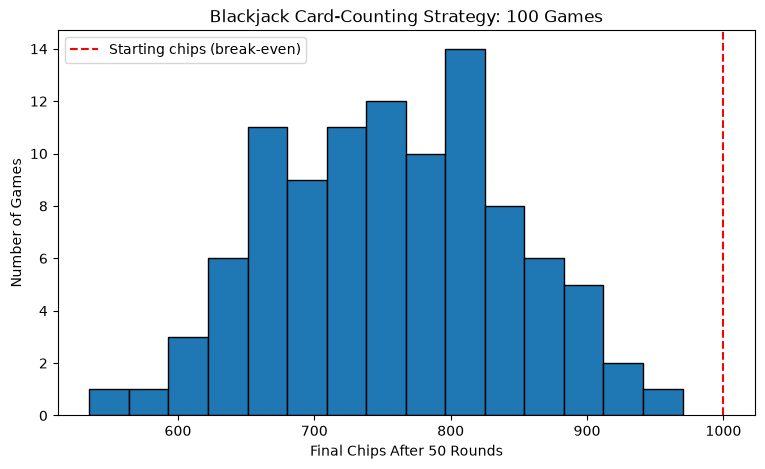

In [25]:
import matplotlib.pyplot as plt
from statistics import mean, stdev

num_games = 100
rounds_per_game = 50
starting_chips = 1000
bet = 10
threshold = 0
winnings = []
final_chips = []
round_counts = []

for i in range(num_games):
    profit, rounds = run_simulation(
        rounds=rounds_per_game,
        starting_chips=starting_chips,
        bet=bet,
        threshold=threshold,
        verbose=False
    )

    winnings.append(profit)
    final_chips.append(starting_chips + profit)
    round_counts.append(rounds)

total_rounds = sum(round_counts)
average_winnings_per_game = mean(winnings)
average_winnings_per_round = sum(winnings) / total_rounds
standard_deviation = stdev(winnings)
winning_games = sum(w > 0 for w in winnings)
losing_games = sum(w < 0 for w in winnings)
break_even_games = sum(w == 0 for w in winnings)
prob_win = winning_games / num_games
prob_loss = losing_games / num_games
prob_break_even = break_even_games / num_games

print("Games played:", num_games)
print("Total rounds played:", total_rounds)
print("Average winnings per game:",
      round(average_winnings_per_game, 2))
print("Average winnings per round:",
      round(average_winnings_per_round, 2))
print("Standard deviation of game winnings:",
      round(standard_deviation, 2))
print("Probability of net winning:",
      f"{prob_win:.2%}")
print("Probability of net losing:",
      f"{prob_loss:.2%}")
print("Probability of breaking even:",
      f"{prob_break_even:.2%}")


plt.figure(figsize=(9, 5))
plt.hist(final_chips, bins=15, edgecolor="black")
plt.axvline(
    starting_chips,
    color="red",
    linestyle="--",
    label="Starting chips (break-even)"
)

plt.xlabel("Final Chips After 50 Rounds")
plt.ylabel("Number of Games")
plt.title("Blackjack Card-Counting Strategy: 100 Games")
plt.legend()
plt.show()


9. Repeat previous questions scanning the value of the threshold. Try at least 5 different threshold values. Can you find an optimal value?

Threshold   Avg/Round      Std Dev        P(Win)      P(Loss)     
------------------------------------------------------------------
-4          -2.88          83.42          1.00%       99.00%      
-2          -3.99          86.03          0.00%       100.00%     
0           -4.80          86.10          1.00%       99.00%      
2           -5.83          82.96          0.00%       100.00%     
4           -6.79          84.53          0.00%       100.00%     

========== OPTIMAL THRESHOLD ==========
Best threshold: -4
Highest average winnings per round: -2.88


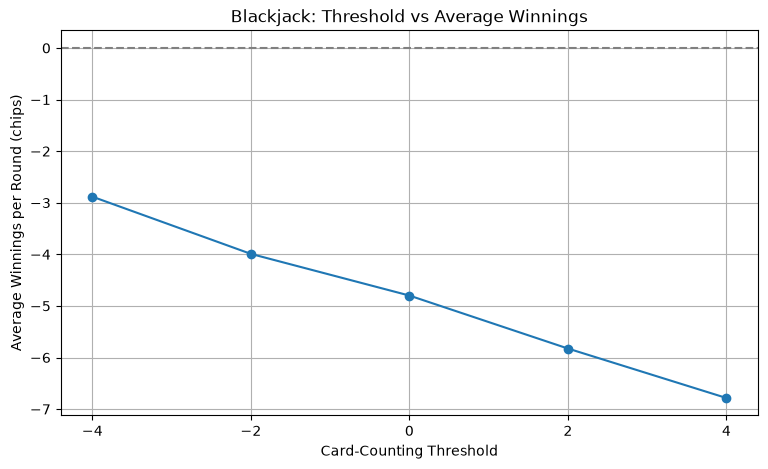

In [26]:
import matplotlib.pyplot as plt
from statistics import mean, stdev

thresholds = [-4, -2, 0, 2, 4]
num_games = 100
rounds_per_game = 50
starting_chips = 1000
bet = 10
results = []
for threshold in thresholds:
    winnings = []
    round_counts = []
    for i in range(num_games):
        profit, rounds = run_simulation(
            rounds=rounds_per_game,
            starting_chips=starting_chips,
            bet=bet,
            threshold=threshold,
            verbose=False
        )

        winnings.append(profit)
        round_counts.append(rounds)
    total_rounds = sum(round_counts)
    avg_per_round = (
        sum(winnings) / total_rounds
        if total_rounds > 0 else 0
    )
    std = stdev(winnings)
    prob_win = sum(w > 0 for w in winnings) / num_games
    prob_loss = sum(w < 0 for w in winnings) / num_games
    results.append({
        "threshold": threshold,
        "average": avg_per_round,
        "std": std,
        "prob_win": prob_win,
        "prob_loss": prob_loss
    })


print(
    f"{'Threshold':<12}"
    f"{'Avg/Round':<15}"
    f"{'Std Dev':<15}"
    f"{'P(Win)':<12}"
    f"{'P(Loss)':<12}"
)

print("-" * 66)

for r in results:
    print(
        f"{r['threshold']:<12}"
        f"{r['average']:<15.2f}"
        f"{r['std']:<15.2f}"
        f"{r['prob_win']:<12.2%}"
        f"{r['prob_loss']:<12.2%}"
    )

best = max(results, key=lambda r: r["average"])
print("\n========== OPTIMAL THRESHOLD ==========")
print("Best threshold:", best["threshold"])
print(
    "Highest average winnings per round:",
    round(best["average"], 2)
)


plt.figure(figsize=(9, 5))
plt.plot(
    [r["threshold"] for r in results],
    [r["average"] for r in results],
    marker="o"
)

plt.axhline(0, color="gray", linestyle="--")
plt.xlabel("Card-Counting Threshold")
plt.ylabel("Average Winnings per Round (chips)")
plt.title("Blackjack: Threshold vs Average Winnings")
plt.xticks(thresholds)
plt.grid(True)
plt.show()


10. Create a new strategy based on web searches or your own ideas. Demonstrate that the new strategy will result in increased or decreased winnings. 

In [27]:
class ImprovedStrategyPlayer(StrategyPlayer):

    def decide_action(self, dealer_card=None):
        total = self.hand.get_value()

        if dealer_card.rank == "A":
            dealer_value = 11
        elif dealer_card.rank in ["J", "Q", "K"]:
            dealer_value = 10
        else:
            dealer_value = int(dealer_card.rank)
        aces = sum(
            card.rank == "A"
            for card in self.hand.cards
        )

        low_total = 0
        for card in self.hand.cards:
            if card.rank == "A":
                low_total += 1
            elif card.rank in ["J", "Q", "K"]:
                low_total += 10
            else:
                low_total += int(card.rank)

        soft = aces > 0 and low_total + 10 <= 21
        if soft:
            if total <= 17:
                return "h"
            if total == 18:
                return "s" if dealer_value <= 8 else "h"
            return "s"
        if total <= 11:
            return "h"

        if total >= 17:
            return "s"

        if total == 12:
            return "s" if 4 <= dealer_value <= 6 else "h"

        if 13 <= total <= 16:
            return "s" if 2 <= dealer_value <= 6 else "h"

        return "s"



Original Strategy:
Average winnings per round: -4.32
Standard deviation: 93.91

Improved Strategy:
Average winnings per round: -0.37
Standard deviation: 69.09

Difference: 3.95
The new strategy increased average winnings.


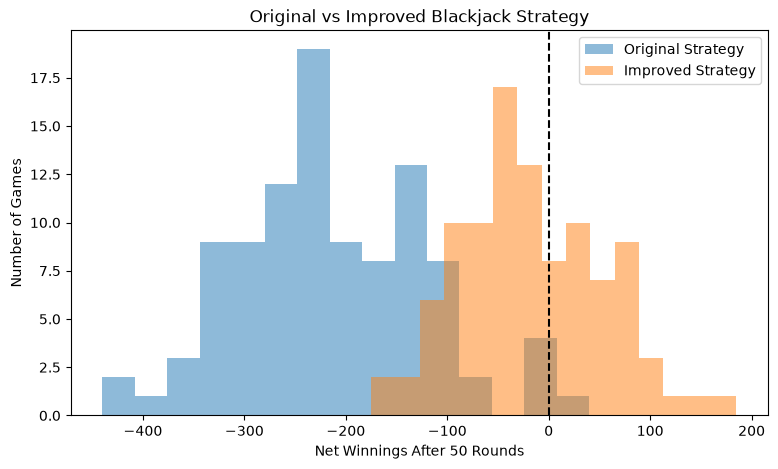

In [28]:
import matplotlib.pyplot as plt
from statistics import stdev

num_games = 100
starting_chips = 1000
bet = 10
def test_strategy(player_class):
    winnings = []
    total_rounds = 0
    for i in range(num_games):
        profit, rounds = run_simulation(
            rounds=50,
            starting_chips=starting_chips,
            bet=bet,
            threshold=0,
            verbose=False,
            player_class=player_class
        )
        winnings.append(profit)
        total_rounds += rounds
    average = sum(winnings) / total_rounds
    standard_deviation = stdev(winnings)

    return winnings, average, standard_deviation

original_winnings, original_avg, original_std = test_strategy(
    StrategyPlayer
)

improved_winnings, improved_avg, improved_std = test_strategy(
    ImprovedStrategyPlayer
)

print("\nOriginal Strategy:")
print("Average winnings per round:", round(original_avg, 2))
print("Standard deviation:", round(original_std, 2))
print("\nImproved Strategy:")
print("Average winnings per round:", round(improved_avg, 2))
print("Standard deviation:", round(improved_std, 2))

difference = improved_avg - original_avg
print("\nDifference:", round(difference, 2))

if difference > 0:
    print("The new strategy increased average winnings.")
elif difference < 0:
    print("The new strategy decreased average winnings.")
else:
    print("Both strategies had equal average winnings.")


plt.figure(figsize=(9, 5))
plt.hist(
    original_winnings,
    bins=15,
    alpha=0.5,
    label="Original Strategy"
)
plt.hist(
    improved_winnings,
    bins=15,
    alpha=0.5,
    label="Improved Strategy"
)

plt.axvline(0, color="black", linestyle="--")
plt.xlabel("Net Winnings After 50 Rounds")
plt.ylabel("Number of Games")
plt.title("Original vs Improved Blackjack Strategy")
plt.legend()
plt.show()
